# Blockwise exact attention

A softmax can be accumulated without keeping a full matrix of attention scores. A running maximum is what makes the partial sums agree with dense attention.

This is the online normalisation calculation used in tiled exact attention. The NumPy example exposes its arithmetic and score-tile sizes. Hardware kernels, backpropagation and runtime benchmarking lie outside this experiment.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def report(columns, rows):
    frame = pd.DataFrame(rows, columns=columns)
    for column in frame.columns:
        if "error" in column.lower() or column == "Change in query norm":
            frame[column] = frame[column].map(lambda value: f"{value:.2e}")
    try:
        from IPython import get_ipython

        interactive = get_ipython() is not None
    except ImportError:
        interactive = False
    if interactive:
        from IPython.display import display

        display(frame.round(5))
    else:
        print(frame.round(5).to_string(index=False))


def softmax(logits, axis=-1):
    shifted = logits - np.max(logits, axis=axis, keepdims=True)
    weights = np.exp(shifted)
    return weights / weights.sum(axis=axis, keepdims=True)


def tiled(q, k, v, block):
    answer = np.empty((len(q), v.shape[1]))
    for i in range(0, len(q), block):
        query = q[i : i + block]
        m = np.full((len(query), 1), -np.inf)
        total = np.zeros_like(m)
        numerator = np.zeros((len(query), v.shape[1]))
        for j in range(0, len(k), block):
            scores = query @ k[j : j + block].T / np.sqrt(k.shape[1])
            new_m = np.maximum(m, scores.max(1, keepdims=True))
            scale = np.exp(m - new_m)
            weights = np.exp(scores - new_m)
            numerator = scale * numerator + weights @ v[j : j + block]
            total = scale * total + weights.sum(1, keepdims=True)
            m = new_m
        answer[i : i + len(query)] = numerator / total
    return answer

## Compare with a dense reference

Unequal query and key lengths and a partial final tile exercise two common indexing errors. A high logit scale tests numerical stability.

In [2]:
rng = np.random.default_rng(73)
q = rng.normal(size=(59, 12)) * 4
k = rng.normal(size=(71, 12)) * 4
v = rng.normal(size=(71, 9))
dense = softmax(q @ k.T / np.sqrt(12)) @ v
sizes = [1, 4, 8, 16, 32, 96]
rows = []
for size in sizes:
    error = float(np.max(np.abs(tiled(q, k, v, size) - dense)))
    assert error < 1e-11
    rows.append((size, min(size, len(q)) * min(size, len(k)), error))
report(["Tile width", "Largest score tile (entries)", "Max abs error vs dense"], rows)

,Tile width,Largest score tile (entries),Max abs error vs dense
0,1,1,2.66e-15
1,4,16,1.78e-15
2,8,64,2.66e-15
3,16,256,1.78e-15
4,32,1024,1.33e-15
5,96,4189,2.22e-15


## Count temporary score entries

The dashed line is the whole dense score matrix. The estimate excludes Q, K, V, output arrays and the running sums.

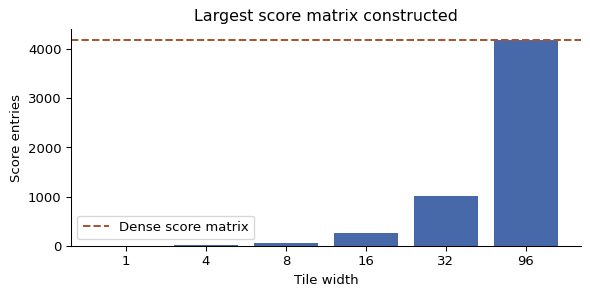

In [3]:
fig, ax = plt.subplots(figsize=(6.1, 3), layout="constrained")
ax.bar([str(v) for v in sizes], [r[1] for r in rows], color="#4768a9")
ax.axhline(len(q) * len(k), color="#a65532", ls="--", label="Dense score matrix")
ax.set(xlabel="Tile width", ylabel="Score entries", title="Largest score matrix constructed")
ax.legend()
plt.show()

## Interpreting the result

The largest temporary score tile shrinks as the block size falls. Arithmetic still includes every query-key pair. A very small block also means more Python loop iterations.

## Exercise

Repeat with very large-magnitude logits and compare against a softmax that omits maximum subtraction.

## References

[Dao et al. (2022), FlashAttention](https://arxiv.org/abs/2205.14135)

[Vaswani et al. (2017), Attention Is All You Need](https://arxiv.org/abs/1706.03762)